# Practice 2.2: numpy

Numpy's main object is the **array** (`ndarray`), a n-dymensional optimised data structure. They are widely used for EEG recordings, MRI Volumes and other multi-dimensional, big data.

In [9]:
# you don't have that module :(
from plot import lineplot

### Creating arrays and converting from pandas

**Syntax**:

```python
import numpy as np

np.array([3, 5, 4])     # from a list  => [3 5 4]
np.arange(5)            # like range()  => [0 1 2 3 4]
np.linspace(0, 1, 3)    # 3 evenly spaced numbers => [0.  0.5 1. ]
np.zeros((2, 3))        # 2 rows, 3 columns of 0  (np.ones() works the same)

# a 2D array (a list of lists)
arr = np.array([[1, 2, 3],
                [4, 5, 6]])  

arr.shape   # => (2, 3) -> rows, columns
arr.ndim    # => 2  -> number of dimensions
arr.dtype   # => int64  -> type of the values

# from pandas
df["mood"].to_numpy()   # one column => 1D array
df.to_numpy()           # the whole table => 2D array
```

**Your tasks ⬇**

In [11]:
import numpy as np
import pandas as pd

# 1. Create an array from the list [3, 5, 4, 6, 2]. Print it, its shape and its dtype.
#    Expected: [3 5 4 6 2] (5,) int64
my_arr = np.array([3, 5, 4, 6, 2])
print(f"{my_arr} {my_arr.shape} {my_arr.dtype}")

# 2. Create an array with the numbers 0 to 9.
#    Expected: [0 1 2 3 4 5 6 7 8 9]
nums = np.arange(10)
print(nums)

# 3. Create 5 evenly spaced numbers from 0 to 1.
#    Expected: [0.   0.25 0.5  0.75 1.  ]
spaced = np.linspace(0, 1, 5)
print(spaced)

# 4. Create a 2D array of zeros with 3 rows and 4 columns. Check its shape.
#    Expected: (3, 4)
matrix = np.zeros((3, 4))
print(f"{matrix}\n{matrix.shape}")

# 5. Load data/esm_simulated.csv with pandas and convert the "mood" column to a numpy array.
#    What is its type and shape?
#    Expected: <class 'numpy.ndarray'> (78,)
df_esm = pd.read_csv("data/esm_simulated.csv")
mood_np = df_esm["mood"].to_numpy()
print(f"type: {type(mood_np)}, shape: {mood_np.shape}")

print(mood_np.shape)
print(type(mood_np))


[3 5 4 6 2] (5,) int64
[0 1 2 3 4 5 6 7 8 9]
[0.   0.25 0.5  0.75 1.  ]
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]
 [0. 0. 0. 0.]]
(3, 4)
type: <class 'numpy.ndarray'>, shape: (78,)
(78,)
<class 'numpy.ndarray'>


### Simulated EEG data

For the rest of this notebook we use a simulated EEG recording. Run the cell below to create it. The code that simulates the data is in the module `eeg_simulation.py` (have a look!).

- `eeg`: one trial, **4 channels × 200 samples** (in µV)
- `channels`: the channel names `["Fz", "Cz", "Pz", "Oz"]`
- `times`: the time of each sample in seconds (-0.5 to 1.49). The stimulus appears at 0 s.
- `trials`: 20 trials, **20 × 4 × 200**

A single channel: eeg[0]:


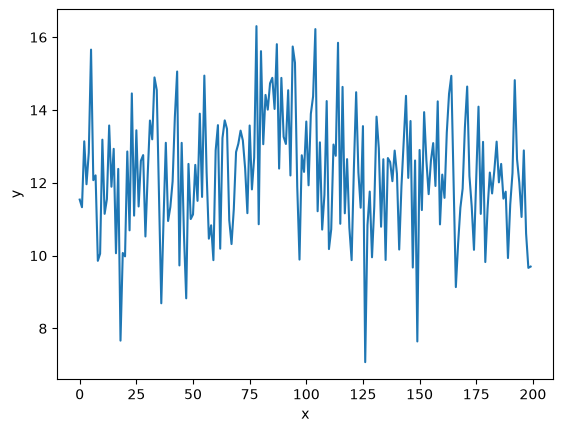

In [14]:
import numpy as np
from eeg_simulation import simulate_eeg

trials, channels, times = simulate_eeg()  # 20 trials x 4 channels x 200 samples
eeg = trials[0]                           # a single trial: 4 channels x 200 samples

# extract a single channel
eeg_ch0 = eeg[0]

print("A single channel: eeg[0]:")
lineplot(eeg_ch0)

### Indexing, slicing and copy()

Indexing works like with lists, but with **one index per dimension**, separated by commas:

```python
arr = np.array([[1, 2, 3],
                [4, 5, 6]])

arr[0]      # first row => [1 2 3]
arr[1, 2]   # row 1, column 2 => 6
arr[:, 0]   # all rows, column 0 => [1 4]
arr[0, 1:]  # row 0, columns 1 to end => [2 3]
arr[-1]     # the last row => [4, 5, 6]

```

**Careful**: a slice is not a copy! It's a **view** on the same data. If you change the slice, the original array changes too (without any warning). Use `.copy()` if you need an independent copy:

```python
copied = arr[0].copy()
```

**Your tasks ⬇**

In [38]:
# first 5 samples of all channels
head = eeg[:, :5]

# 1. What is the shape of `eeg`? How many channels and samples are there?
#    Expected: (4, 200)
print(eeg.shape)
# 4 rows -> 4 channels
# 200 columns -> 200 smaples per channel

# 2. Get the whole signal of the first channel (Fz). What is its shape?
#    Expected: (200,)
fz = eeg[0]
print(fz.shape)
# (200,) -> 200 samples

# 3. Get the value of channel Pz (index 2) at sample 100.
#    Expected: 2.87
val = eeg[2, 100]
print(val)

# 4. The stimulus appears at sample 50. Get all channels for the samples before the stimulus.
#    Expected shape: (4, 50)
baseline_eeg = eeg[:, :50]
print(baseline_eeg.shape)

# 5. What are the first and the last time points in `times`?
#    Expected: -0.5 1.49
first_time = times[0]
last_time = times[-1]
print(f"times ranges from {first_time} to {last_time}")

# 6. Run the code below. Why does `scores` change? Fix it with .copy().
scores = np.array([1, 2, 3, 4, 5])
first_three = scores[:3].copy()
first_three[0] = 100
print(scores)
print(first_three)
#    Expected after the fix: [1 2 3 4 5]

(4, 200)
(200,)
2.873291116734583
(4, 50)
times ranges from -0.5 to 1.49
[1 2 3 4 5]
[100   2   3]


### Operations: calculating without loops

Operations on arrays are applied to **every element at once** without loops needed:

```python
arr = np.array([1, 2, 3])

arr * 2             # => [2 4 6]
arr + arr           # => [2 4 6]   (element by element)
arr - arr.mean()    # => [-1.  0.  1.]
np.sqrt(arr)        # numpy functions work on whole arrays
np.round(arr / 3, 2) # => [0.33 0.67 1.  ]

[1, 2, 3] * 2  # watch out! for lists this results in [1, 2, 3, 1, 2, 3]
```

**Baseline correction**

EEG channels often have an offset: the signal is shifted up or down. To make channels comparable, we subtract the average of the **baseline** (the time before the stimulus, in our case 50 samples) from the whole signal:

```python
signal = eeg[0]                 # values of first channel
baseline = signal[:50].mean()   # average before the stimulus
corrected = signal - baseline   # subtracted from every sample at once
```

**Your tasks ⬇**

In [ ]:
moods = np.array([3, 5, 4, 6, 2])

# 1. Compare: what is [3, 5, 4, 6, 2] * 2, and what is moods * 2?
print(f"PYTHON: [3, 5, 4, 6, 2] * 2 = {[3, 5, 4, 6, 2] * 2}")
print(f"NUMPY: np.array([3, 5, 4, 6, 2]) * 2 = {moods * 2}")

# PYTHON: [3, 5, 4, 6, 2] * 2 = [3, 5, 4, 6, 2, 3, 5, 4, 6, 2]
# NUMPY: np.array([3, 5, 4, 6, 2]) * 2 = [ 6 10  8 12  4]
# For python lists, the '*' operator multiplies the LENGTH of the list
# In numpy, it operates on each value

# 2. Convert the moods from the 1-7 scale to percent (1 => 0 %, 7 => 100 %).
#       [ think of copy() ! ] <- NO DON'T THINK OF IT THIS IS A MISTAKE
#    Expected: [33.33 66.67 50.   83.33 16.67]

moods_relative = (moods - 1) / 6
print(moods)
print(moods_relative)

# 3. Reverse-code the moods on the 1-7 scale (1 => 7, 2 => 6, ...).
#    Expected: [5 3 4 2 6]

# 4. Baseline-correct channel Fz (index 0) of `eeg`:
#    - what is the average of its baseline (first 50 samples)?
#    - subtract it from the whole signal and store the result as `fz_corrected`
#    - check: the average of the baseline of `fz_corrected` should now be 0

PYTHON: [3, 5, 4, 6, 2] * 2 = [3, 5, 4, 6, 2, 3, 5, 4, 6, 2]
NUMPY: np.array([3, 5, 4, 6, 2]) * 2 = [ 6 10  8 12  4]
[3 5 4 6 2]
[0.33333333 0.66666667 0.5        0.83333333 0.16666667]


### How fast is numpy?

Let's measure it! `%%timeit` at the top of a cell runs the cell many times and reports how long it takes on average. Run the three cells below and compare the times.

In [ ]:
# one million numbers, as a list and as an array
numbers_list = list(range(1000000))
numbers_array = np.arange(1000000)

In [ ]:
%%timeit
# square every number with a loop
squares = []
for x in numbers_list:
    squares.append(x ** 2)

In [ ]:
%%timeit
# square every number with numpy
squares = numbers_array ** 2

### Boolean masks

A comparison with an array gives an array of `True`/`False` values: a **mask**. Use the mask to select only the matching values:

```python
arr = np.array([3, 5, 4, 6, 2])

arr > 4             # => [False True False True False]
arr[arr > 4]        # => [5 6]
(arr > 4).sum()     # => 2  (True counts as 1)

arr[(arr >= 3) & (arr <= 4)] # => [3 4]  combine conditions with & (and), | (or)
```

**Watch out**: with arrays, use `&` and `|` (bitwise operators) instead of `and` and `or`, and put each condition in brackets!

**Your tasks ⬇**

In [ ]:
moods = np.array([3, 5, 4, 6, 2])

# 1. Create a mask that is True for all moods above 4. Print it.
#    Expected: [False  True False  True False]

# 2. Use the mask to get only the moods above 4. How many are there?
#    Expected: [5 6] and 2

# 3. Get all moods from 3 to 5 (including 3 and 5).
#    Expected: [3 5 4]

# 4. Bonus: Here is the baseline-corrected signal of channel Pz:
pz = eeg[2] - eeg[2, :50].mean()
#    How many samples of `pz` are above 5 µV?

### Summary functions and axis

**Syntax**:

```python
arr.mean()    # also: .std(), .min(), .max(), .sum()
np.mean(arr)  # the same, as a function
np.argmax(arr)  # the POSITION of the largest value (np.argmin: smallest)
```

For arrays with more than one dimension, `axis` decides **in which direction** we summarize:

```python
arr = np.array([[1, 2, 3],
                [4, 5, 6]])

arr.mean()          # all values          => 3.5
arr.mean(axis=0)    # along columns       => [2.5 3.5 4.5]  (one value per column)
arr.mean(axis=1)    # along each row      => [2. 5.] (one value per row)
```

For `eeg` (channels × samples): `axis=1` gives **one value per channel**, `axis=0` gives **one value per time point**.

**Your tasks ⬇**

In [ ]:
# 1. What are the mean, the minimum and the maximum of all values in `eeg`?

# 2. Calculate the mean of each channel. What is the shape of the result?

# 3. Calculate the mean across all channels at each time point. What is the shape?

# 4. Find the maximum of each channel. 
